In [1]:
%matplotlib inline
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.utils.class_weight import compute_sample_weight

SEED = 42
TARGET = "Target_local_recurrence"
warnings.simplefilter("error", ConvergenceWarning)

In [2]:
# Выборки и подготовка признаков из недели 8: разбиение с random_state = 42,
# заполнение пропусков, нормализация и кодирование настроены только на обучающей выборке.
train = pd.read_csv("../w8/prepared/train.csv")
validation = pd.read_csv("../w8/prepared/validation.csv")
test = pd.read_csv("../w5/test.csv", usecols=["Patient_ID", TARGET])  # признаки теста не загружаются
assert set(train.Patient_ID).isdisjoint(validation.Patient_ID)
assert set(test.Patient_ID).isdisjoint(set(train.Patient_ID) | set(validation.Patient_ID))

samples = {"Обучение": train, "Валидация": validation, "Тест (отложен)": test}
display(pd.DataFrame({name: {"Пациентов": len(frame), "Исход 1": int(frame[TARGET].sum())}
                      for name, frame in samples.items()}).T)

features = train.columns.drop(["Patient_ID", TARGET])
X_train, y_train = train[features], train[TARGET]
X_validation, y_validation = validation[features], validation[TARGET]
print(f"Признаков: {len(features)}")

,Пациентов,Исход 1
Обучение,84,7
Валидация,21,2
Тест (отложен),35,3


Признаков: 36


In [3]:
C, MAX_ITER = 0.1, 2000
weights = compute_sample_weight("balanced", y_train)

def network(activation, seed):
    # alpha = 1 / C: та же сила L2-штрафа, что у логистической регрессии
    return MLPClassifier(hidden_layer_sizes=(16,), activation=activation, solver="lbfgs",
                         alpha=1 / C, max_iter=MAX_ITER, random_state=seed)

def evaluate(model):
    return {"Обучение": model.score(X_train, y_train),
            "Валидация": model.score(X_validation, y_validation),
            "Итераций": int(np.max(model.n_iter_))}

models = {
    "Логистическая регрессия": LogisticRegression(C=C, max_iter=MAX_ITER),
    "Нейронная сеть (ReLU)": network("relu", SEED),
    "Нейронная сеть без нелинейности (f(x) = x)": network("identity", SEED),
}
for model in models.values():
    model.fit(X_train, y_train, sample_weight=weights)

table = pd.DataFrame({name: evaluate(model) for name, model in models.items()}).T
assert (table["Итераций"] < MAX_ITER).all()
display(table.round(4).astype({"Итераций": int}))

print(f"Всегда нет рецидива: обучение {1 - y_train.mean():.4f}, валидация {1 - y_validation.mean():.4f}")
for name, model in models.items():
    predicted = model.predict(X_validation)
    print(f"{name}: предсказано рецидивов на валидации {predicted.sum()}, "
          f"верно {(predicted & y_validation).sum()} из {y_validation.sum()}")

,Обучение,Валидация,Итераций
Логистическая регрессия,0.9048,0.7619,15
Нейронная сеть (ReLU),0.9286,0.7619,238
Нейронная сеть без нелинейности (f(x) = x),0.9048,0.8095,21


Всегда нет рецидива: обучение 0.9167, валидация 0.9048
Логистическая регрессия: предсказано рецидивов на валидации 3, верно 0 из 2
Нейронная сеть (ReLU): предсказано рецидивов на валидации 3, верно 0 из 2
Нейронная сеть без нелинейности (f(x) = x): предсказано рецидивов на валидации 2, верно 0 из 2


In [4]:
seeds = range(20)
nets = [network("relu", seed).fit(X_train, y_train, sample_weight=weights) for seed in seeds]
results = pd.DataFrame([evaluate(net) for net in nets], index=pd.Index(seeds, name="random_state"))
assert (results["Итераций"] < MAX_ITER).all()
display(results.round(4))
display(results.agg(["mean", "std", "min", "max"]).round(4))

predictions = np.array([net.predict(X_validation) for net in nets])
probabilities = np.array([net.predict_proba(X_validation)[:, 1] for net in nets])
same_as_logistic = (predictions == models["Логистическая регрессия"].predict(X_validation)).all(axis=1)
print(f"Предсказания на валидации совпадают с логистической регрессией у {same_as_logistic.sum()} из {len(nets)} сетей")
print(f"Наибольший разброс вероятности рецидива у одного пациента: {np.ptp(probabilities, axis=0).max():.4f}")

,Обучение,Валидация,Итераций
random_state,,,
0,0.9286,0.7619,170
1,0.9167,0.7619,224
2,0.9286,0.7619,402
3,0.9286,0.7619,191
4,0.9286,0.7619,195
5,0.9286,0.7619,243
6,0.9286,0.7619,232
7,0.9286,0.7619,213
8,0.9286,0.7619,181


,Обучение,Валидация,Итераций
mean,0.9262,0.7619,222.4000
std,0.0049,0.0000,61.6445
min,0.9167,0.7619,139.0000
max,0.9286,0.7619,402.0000


Предсказания на валидации совпадают с логистической регрессией у 20 из 20 сетей
Наибольший разброс вероятности рецидива у одного пациента: 0.0359


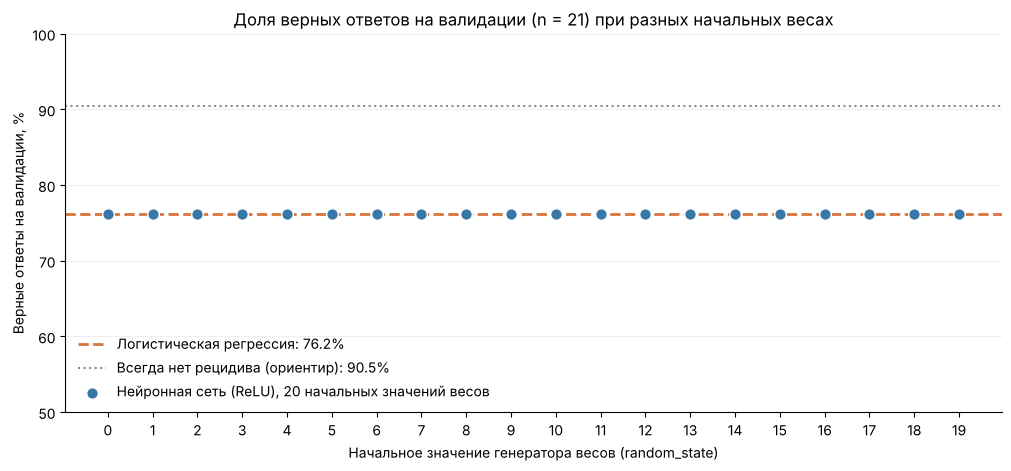

In [5]:
logistic = table.loc["Логистическая регрессия", "Валидация"]
fig, ax = plt.subplots(figsize=(10, 4.6), layout="constrained")
ax.axhline(logistic * 100, color="#D7743B", linewidth=2, linestyle="--",
           label=f"Логистическая регрессия: {logistic:.1%}")
ax.axhline((1 - y_validation.mean()) * 100, color="#8A8A8A", linewidth=1.5, linestyle=":",
           label=f"Всегда нет рецидива (ориентир): {1 - y_validation.mean():.1%}")
ax.scatter(results.index, results["Валидация"] * 100, s=70, color="#3678A8", edgecolor="white", zorder=3,
           label=f"Нейронная сеть (ReLU), {len(nets)} начальных значений весов")
ax.set(xlabel="Начальное значение генератора весов (random_state)", ylabel="Верные ответы на валидации, %",
       xticks=list(seeds), ylim=(50, 100),
       title=f"Доля верных ответов на валидации (n = {len(validation)}) при разных начальных весах")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.2)
ax.legend(frameon=False, loc="lower left")
plt.show()

## Выводы

На валидации (21 пациент, 2 рецидива) нейронная сеть с 16 нейронами ReLU не лучше логистической регрессии: у обеих доля верных ответов 0,762, предсказания совпадают, и ни одна не нашла ни одного из двух рецидивов. Обе уступают постоянному прогнозу «нет рецидива» (0,905), то есть ошибки — в основном ложные тревоги.

Без нелинейности сеть становится линейной моделью: доля на обучении снижается с 0,929 до 0,905, а на валидации растёт до 0,810, потому что ложных тревог две вместо трёх. Нелинейность лишь точнее подгоняет обучающие данные и обобщение не улучшает.

От начальных весов результат почти не зависит: у 20 сетей доля на валидации одна и та же (0,762, стандартное отклонение 0), предсказания одинаковы, на обучении доля 0,917–0,929, а вероятность рецидива у пациента меняется не больше чем на 0,036. Все сети остановились за 139–402 итераций из 2000.

Признаки переобучения есть: разница долей на обучении и валидации 0,143 у логистической регрессии, 0,167 у сети и 0,095 у сети без нелинейности. Однако ошибка на одном пациенте валидации меняет долю на 0,048, поэтому различия между моделями в одного–двух пациентов ненадёжны.